# Standard QML — UTS Prediction (PAQFE baseline)

This notebook trains the **Standard QML** baseline described in the proposal:

`X → normalization → standard (angle) encoding → variational circuit → UTS`

It reuses the **exact same** feature list, target, observation-level split (`random_state=42`,
`test_size=0.20`), and composition-level `GroupKFold` protocol (5 splits × 5 repeats, seeds 42–46)
as `Classical_Models.ipynb`, so results are directly comparable to your Random Forest / SVR numbers.

**How to run in Colab:**
1. Runtime → New notebook (or upload this file directly: File → Upload notebook).
2. Run the install cell first (takes ~1–2 min).
3. Upload `PAQFE_UTS_Dataset_Corrected (1).xlsx` when prompted in the "Load dataset" cell
   (or mount Google Drive and edit the path — instructions in that cell).
4. Run all cells top to bottom.

No GPU / real quantum hardware needed — everything runs on a classical simulator
(`lightning.qubit`), CPU runtime is fine.

In [ ]:
# ============================================================
# 1. Install dependencies (Colab: run this cell first)
# ============================================================
!pip install -q pennylane pennylane-lightning torch pandas openpyxl scikit-learn matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.7 MB/s eta 0:00:00


In [ ]:
# ============================================================
# 2. Imports & global config
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import pennylane as qml

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

torch.set_default_dtype(torch.float64)  # PennyLane simulators are more stable in float64

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)


## 3. Load dataset

Same sheet (`B_Model_Ready`) and same feature/target columns as `Classical_Models.ipynb`.
If you're running fresh in Colab, either:
- **Option A (quick):** run the upload cell below and pick the `.xlsx` file from your computer, or
- **Option B (Drive):** mount Drive and point `file_path` at the file's Drive path instead.

In [ ]:
# Option A: manual upload (uncomment if not using Drive)
from google.colab import files
uploaded = files.upload()  # choose "PAQFE_UTS_Dataset_Corrected (1).xlsx" in the dialog

file_path = list(uploaded.keys())[0]

# Option B: Google Drive (uncomment instead of Option A if you prefer)
# from google.colab import drive
# drive.mount('/content/drive')
# file_path = "/content/drive/MyDrive/<path-to-file>/PAQFE_UTS_Dataset_Corrected (1).xlsx"

df = pd.read_excel(file_path, sheet_name="B_Model_Ready")
print("Dataset shape:", df.shape)
df.head()


Saving PAQFE_UTS_Dataset_Corrected (1).xlsx to PAQFE_UTS_Dataset_Corrected (1) (1).xlsx
Dataset shape: (49, 25)


,Observation_ID,Al,Co,Cr,Fe,Ni,Al_norm,Co_norm,Cr_norm,Fe_norm,...,delta,Omega,dchi,Mean_Tm,OSHE,NVC,Temperature_C,Strain_rate,log10_Strain_rate,UTS_MPa
0,OBS_001,0.000,0.250,0.250,0.250,0.250,0.000000,0.250000,0.250000,0.250000,...,1.103880,5.752837,0.096695,1871.750000,NaN,NaN,900,0.001,-3.0,130.0
1,OBS_002,0.048,0.238,0.238,0.238,0.238,0.048000,0.238000,0.238000,0.238000,...,3.076890,3.685665,0.104482,1826.714000,NaN,NaN,900,0.001,-3.0,148.0
2,OBS_003,0.111,0.222,0.222,0.222,0.222,0.111111,0.222222,0.222222,0.222222,...,4.328494,2.557021,0.112546,1767.500000,NaN,NaN,900,0.001,-3.0,172.0
3,OBS_004,0.130,0.217,0.217,0.217,0.217,0.130261,0.217435,0.217435,0.217435,...,4.604955,2.349226,0.114579,1749.533066,NaN,NaN,900,0.001,-3.0,188.0
4,OBS_005,0.200,0.200,0.200,0.200,0.200,0.200000,0.200000,0.200000,0.200000,...,5.376204,1.829117,0.120565,1684.100000,NaN,NaN,900,0.001,-3.0,215.0


In [ ]:
# ============================================================
# 4. Features / target — identical to Classical_Models.ipynb
# ============================================================
FEATURES = [
    "xAl",
    "VEC",
    "dHmix",
    "dSmix",
    "delta",
    "Omega",
    "dchi",
    "Mean_Tm",
    "Temperature_C",
    "log10_Strain_rate"
]
TARGET = "UTS_MPa"

N_QUBITS = len(FEATURES)  # 10 — one qubit per feature (standard angle encoding)

X_all = df[FEATURES].copy()
y_all = df[TARGET].copy()

print("Features:", FEATURES)
print("N qubits:", N_QUBITS)


Features: ['xAl', 'VEC', 'dHmix', 'dSmix', 'delta', 'Omega', 'dchi', 'Mean_Tm', 'Temperature_C', 'log10_Strain_rate']
N qubits: 10


In [ ]:
# ============================================================
# 5. Composition grouping — identical to Classical_Models.ipynb
#    (needed for the composition-level GroupKFold protocol)
# ============================================================
composition_cols = ["Al_norm", "Co_norm", "Cr_norm", "Fe_norm", "Ni_norm"]

df["Composition_Group"] = (
    df[composition_cols]
    .round(3)
    .astype(str)
    .agg("_".join, axis=1)
)

print("Unique compositions:", df["Composition_Group"].nunique())


Unique compositions: 14


## 6. Quantum model definition

- **Encoding:** `AngleEmbedding` (RY rotation per feature) — one qubit per feature, 10 qubits total.
  This is the "standard" unstructured encoding; PAQFE-QML will later replace *only* this stage
  with a physics-grouped encoding while keeping everything below identical.
- **Ansatz:** `StronglyEntanglingLayers`, depth 3 — kept fixed across Standard QML and PAQFE-QML.
- **Readout:** expectation value of PauliZ on every qubit → small trainable linear layer
  (`nn.Linear(N_QUBITS, 1)`) maps the 10 expectation values to a single continuous UTS prediction
  (needed because UTS is unbounded, unlike a raw `[-1, 1]` expectation value).

In [ ]:
# ============================================================
# 6. Quantum circuit + hybrid torch model
# ============================================================
N_LAYERS = 3

dev = qml.device("lightning.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="adjoint")
def circuit(inputs, weights):
    qml.templates.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.templates.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS, n_wires=N_QUBITS)}


def make_model(seed):
    torch.manual_seed(seed)
    qlayer = qml.qnn.TorchLayer(circuit, weight_shapes)
    model = nn.Sequential(qlayer, nn.Linear(N_QUBITS, 1))
    return model


## 7. Reusable training / evaluation function

Trains on standardized features and standardized target (inverse-transformed before computing
MAE / RMSE / R² so the reported numbers are in MPa, comparable to RF/SVR).

In [ ]:
# ============================================================
# 7. Training function
# ============================================================
def train_standard_qml(
    X_train, y_train, X_test, y_test,
    seed=42, n_epochs=200, lr=0.02, verbose=False
):
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train_s = x_scaler.fit_transform(X_train)
    X_test_s = x_scaler.transform(X_test)

    y_train_s = y_scaler.fit_transform(np.array(y_train).reshape(-1, 1)).flatten()

    X_train_t = torch.tensor(X_train_s, dtype=torch.float64)
    y_train_t = torch.tensor(y_train_s, dtype=torch.float64).reshape(-1, 1)
    X_test_t = torch.tensor(X_test_s, dtype=torch.float64)

    model = make_model(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(n_epochs):
        optimizer.zero_grad()
        preds = model(X_train_t)
        loss = loss_fn(preds, y_train_t)
        loss.backward()
        optimizer.step()

        if verbose and (epoch + 1) % 50 == 0:
            print(f"  epoch {epoch+1}/{n_epochs} — loss {loss.item():.4f}")

    with torch.no_grad():
        test_preds_s = model(X_test_t).numpy().flatten()

    test_preds = y_scaler.inverse_transform(test_preds_s.reshape(-1, 1)).flatten()

    mae = mean_absolute_error(y_test, test_preds)
    rmse = np.sqrt(mean_squared_error(y_test, test_preds))
    r2 = r2_score(y_test, test_preds)

    return {"MAE": mae, "RMSE": rmse, "R2": r2, "y_pred": test_preds}


## 8. Observation-level Standard QML

Same split as the classical baselines: `train_test_split(..., test_size=0.20, random_state=42)`.
Because quantum-circuit training is stochastic (random weight init + optimizer), we repeat with
5 different init seeds on the **same fixed split** and report mean ± SD, plus keep the seed-42 run
as the single "headline" number in the same shape as your RF/SVR table.

In [ ]:
# ============================================================
# 8. Observation-level protocol
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_SEED
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

N_SEED_REPEATS = 5
obs_repeat_scores = []
obs_last_preds = None

for i, seed in enumerate(range(RANDOM_SEED, RANDOM_SEED + N_SEED_REPEATS)):
    print(f"\n--- Standard QML observation-level | init seed {seed} ---")
    result = train_standard_qml(X_train, y_train, X_test, y_test, seed=seed, n_epochs=200, verbose=True)
    obs_repeat_scores.append({"Seed": seed, "MAE": result["MAE"], "RMSE": result["RMSE"], "R2": result["R2"]})
    if seed == RANDOM_SEED:
        obs_last_preds = result["y_pred"]
    print(f"  MAE={result['MAE']:.4f}  RMSE={result['RMSE']:.4f}  R2={result['R2']:.4f}")

obs_repeat_df = pd.DataFrame(obs_repeat_scores)
obs_repeat_df


Training samples: 39
Testing samples: 10

--- Standard QML observation-level | init seed 42 ---
  epoch 50/200 — loss 0.0940
  epoch 100/200 — loss 0.0511
  epoch 150/200 — loss 0.0473
  epoch 200/200 — loss 0.0462
  MAE=207.8663  RMSE=260.4988  R2=0.2984

--- Standard QML observation-level | init seed 43 ---
  epoch 50/200 — loss 0.0885
  epoch 100/200 — loss 0.0473
  epoch 150/200 — loss 0.0461
  epoch 200/200 — loss 0.0461
  MAE=174.5447  RMSE=224.2386  R2=0.4801

--- Standard QML observation-level | init seed 44 ---
  epoch 50/200 — loss 0.0660
  epoch 100/200 — loss 0.0481
  epoch 150/200 — loss 0.0465
  epoch 200/200 — loss 0.0461
  MAE=207.7075  RMSE=260.2675  R2=0.2996

--- Standard QML observation-level | init seed 45 ---
  epoch 50/200 — loss 0.0775
  epoch 100/200 — loss 0.0510
  epoch 150/200 — loss 0.0482
  epoch 200/200 — loss 0.0472
  MAE=249.3675  RMSE=319.6931  R2=-0.0567

--- Standard QML observation-level | init seed 46 ---
  epoch 50/200 — loss 0.0948
  epoch 100/20

,Seed,MAE,RMSE,R2
0,42,207.866266,260.498783,0.298395
1,43,174.544669,224.238628,0.480121
2,44,207.707456,260.267548,0.299640
3,45,249.367506,319.693113,-0.056690
4,46,250.148303,323.520274,-0.082142


In [ ]:
print("========================================")
print("STANDARD QML — OBSERVATION LEVEL (Mean ± SD)")
print("========================================")
print(f"MAE  : {obs_repeat_df['MAE'].mean():.4f} ± {obs_repeat_df['MAE'].std():.4f}")
print(f"RMSE : {obs_repeat_df['RMSE'].mean():.4f} ± {obs_repeat_df['RMSE'].std():.4f}")
print(f"R2   : {obs_repeat_df['R2'].mean():.4f} ± {obs_repeat_df['R2'].std():.4f}")

print("\nHeadline run (seed=42), directly comparable to your RF/SVR single-run table:")
print(f"MAE  : {obs_repeat_df.iloc[0]['MAE']:.4f}")
print(f"RMSE : {obs_repeat_df.iloc[0]['RMSE']:.4f}")
print(f"R2   : {obs_repeat_df.iloc[0]['R2']:.4f}")


STANDARD QML — OBSERVATION LEVEL (Mean ± SD)
MAE  : 217.9268 ± 32.0718
RMSE : 277.6437 ± 42.7808
R2   : 0.1879 ± 0.2464

Headline run (seed=42), directly comparable to your RF/SVR single-run table:
MAE  : 207.8663
RMSE : 260.4988
R2   : 0.2984


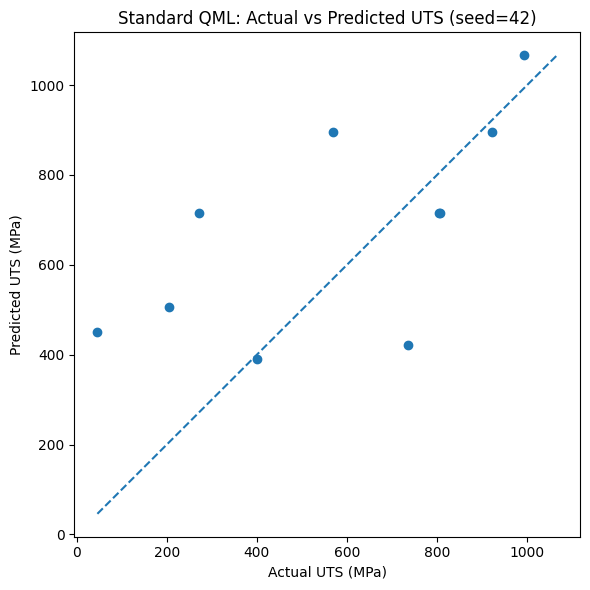

In [ ]:
# Actual vs Predicted (seed=42 run) — same style as your RF/SVR plots
plt.figure(figsize=(6, 6))
plt.scatter(y_test, obs_last_preds)

min_val = min(y_test.min(), obs_last_preds.min())
max_val = max(y_test.max(), obs_last_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual UTS (MPa)")
plt.ylabel("Predicted UTS (MPa)")
plt.title("Standard QML: Actual vs Predicted UTS (seed=42)")
plt.tight_layout()
plt.show()


## 9. Composition-level Standard QML

Identical protocol to the classical notebook: `GroupKFold(n_splits=5)`, 5 repeats,
`random_state = RANDOM_SEED + repeat` (seeds 42–46), grouped on `Composition_Group`.
Out-of-fold predictions are pooled per repeat before computing metrics, exactly as before.

This will take longer than the observation-level cell (5 repeats × 5 folds = 25 training runs).

In [ ]:
# ============================================================
# 9. Composition-level protocol
# ============================================================
X_grp = df[FEATURES].copy()
y_grp = df[TARGET].copy()
groups = df["Composition_Group"].copy()

n_repeats = 5
n_splits = 5

qml_repeat_scores = []

for repeat in range(n_repeats):
    seed = RANDOM_SEED + repeat
    print(f"\n========== REPEAT {repeat + 1} (seed={seed}) ==========")

    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    qml_true, qml_pred_all = [], []

    for fold, (train_idx, test_idx) in enumerate(gkf.split(X_grp, y_grp, groups), start=1):
        X_train_f = X_grp.iloc[train_idx]
        X_test_f = X_grp.iloc[test_idx]
        y_train_f = y_grp.iloc[train_idx]
        y_test_f = y_grp.iloc[test_idx]

        result = train_standard_qml(X_train_f, y_train_f, X_test_f, y_test_f, seed=seed, n_epochs=150)

        qml_true.extend(list(y_test_f))
        qml_pred_all.extend(list(result["y_pred"]))

        print(f"Fold {fold} completed")

    mae = mean_absolute_error(qml_true, qml_pred_all)
    rmse = np.sqrt(mean_squared_error(qml_true, qml_pred_all))
    r2 = r2_score(qml_true, qml_pred_all)

    qml_repeat_scores.append({"Repeat": repeat + 1, "MAE": mae, "RMSE": rmse, "R2": r2})
    print(f"Repeat {repeat + 1} completed — MAE={mae:.4f} RMSE={rmse:.4f} R2={r2:.4f}")

qml_repeat_results = pd.DataFrame(qml_repeat_scores)
qml_repeat_results



========== REPEAT 1 (seed=42) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 1 completed — MAE=197.7084 RMSE=277.0089 R2=0.5083

========== REPEAT 2 (seed=43) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 2 completed — MAE=196.2214 RMSE=289.4497 R2=0.4631

========== REPEAT 3 (seed=44) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 3 completed — MAE=203.4056 RMSE=299.7203 R2=0.4244

========== REPEAT 4 (seed=45) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 4 completed — MAE=214.0085 RMSE=290.1573 R2=0.4605

========== REPEAT 5 (seed=46) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 5 completed — MAE=128.2578 RMSE=200.9325 R2=0.7413


,Repeat,MAE,RMSE,R2
0,1,197.708413,277.008934,0.508297
1,2,196.221373,289.449663,0.463140
2,3,203.405642,299.720302,0.424365
3,4,214.008470,290.157257,0.460512
4,5,128.257782,200.932497,0.741289


In [ ]:
print("======================================")
print("FINAL COMPOSITION-LEVEL STANDARD QML")
print("======================================")
print(f"MAE  : {qml_repeat_results['MAE'].mean():.4f} ± {qml_repeat_results['MAE'].std():.4f}")
print(f"RMSE : {qml_repeat_results['RMSE'].mean():.4f} ± {qml_repeat_results['RMSE'].std():.4f}")
print(f"R2   : {qml_repeat_results['R2'].mean():.4f} ± {qml_repeat_results['R2'].std():.4f}")


FINAL COMPOSITION-LEVEL STANDARD QML
MAE  : 187.9203 ± 34.0761
RMSE : 271.4537 ± 40.2392
R2   : 0.5195 ± 0.1275


## 10. Save results

Writes an Excel file in the same shape as `Classical_ML_Results_Final.xlsx`, so you can merge it
with your existing RF/SVR results (or just append these sheets into that same workbook).

In [ ]:
# ============================================================
# 10. Save results
# ============================================================
obs_headline = pd.DataFrame({
    "Model": ["Standard QML"],
    "MAE": [obs_repeat_df.iloc[0]["MAE"]],
    "RMSE": [obs_repeat_df.iloc[0]["RMSE"]],
    "R2": [obs_repeat_df.iloc[0]["R2"]],
})

comp_summary = pd.DataFrame({
    "Model": ["Standard QML"],
    "MAE (Mean)": [qml_repeat_results["MAE"].mean()],
    "MAE (SD)": [qml_repeat_results["MAE"].std()],
    "RMSE (Mean)": [qml_repeat_results["RMSE"].mean()],
    "RMSE (SD)": [qml_repeat_results["RMSE"].std()],
    "R2 (Mean)": [qml_repeat_results["R2"].mean()],
    "R2 (SD)": [qml_repeat_results["R2"].std()],
})

with pd.ExcelWriter("Standard_QML_Results.xlsx", engine="openpyxl") as writer:
    obs_headline.to_excel(writer, sheet_name="Observation_Level", index=False)
    obs_repeat_df.to_excel(writer, sheet_name="Observation_Seed_Repeats", index=False)
    comp_summary.to_excel(writer, sheet_name="Composition_Level", index=False)
    qml_repeat_results.to_excel(writer, sheet_name="Composition_Repeated_Runs", index=False)

print("Saved: Standard_QML_Results.xlsx")

from google.colab import files
files.download("Standard_QML_Results.xlsx")


Saved: Standard_QML_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>